## Basic 2 Stage Model 
 
#### Stage 1: Macroeconomic forecast of market-wide rent

This notebook constructs a basic two-stage housing-rent model. Stage 1 forecasts the monthly market-wide mean rent using only information available from macroeconomic indicators. Stage 2 can later use this forecast as a market-condition feature for an individual-property model.

In the first stage, the target is aggregated to monthly mean rent because the macroeconomic features are monthly and are shared by all properties. A chronological split is used to avoid future information leaking into training.

## 1. Load and align the data

We join the rental observations and macroeconomic data by calendar month. Housing price and private-rent indexes are deliberately excluded from the predictors because this stage is intended to measure the predictive contribution of broader macroeconomic conditions.

In [34]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from lightgbm import LGBMRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

HERE = Path.cwd().resolve()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / 'data' / 'original_dataset').exists())
rent_path = ROOT / 'data' / 'original_dataset' / 'train.csv'
macro_path = ROOT / 'data' / 'original_dataset' / 'auxiliary' / 'sg-macro-features-monthly.csv'
access_path = ROOT / 'data' / 'original_dataset' / 'auxiliary' / 'hdb_features_with_accessibility.csv'
rent = pd.read_csv(rent_path)
macro = pd.read_csv(macro_path, parse_dates=['RENT_APPROVAL_DATE'])
rent['MONTH'] = pd.to_datetime(rent['RENT_APPROVAL_DATE']).dt.to_period('M').dt.to_timestamp()
rent['MONTHLY_RENT'] = pd.to_numeric(rent['MONTHLY_RENT'], errors='coerce')
monthly_rent = (rent.dropna(subset=['MONTH', 'MONTHLY_RENT'])
                .groupby('MONTH')['MONTHLY_RENT'].mean()
                .rename('mean_monthly_rent').reset_index())
macro = macro.rename(columns={'RENT_APPROVAL_DATE': 'MONTH'})
macro['MONTH'] = macro['MONTH'].dt.to_period('M').dt.to_timestamp()
macro_cols = [
    'MACRO_CPI_EX_ACCOM_YOY', 'MACRO_SORA_3M_PCT',
    'MACRO_REAL_GDP_YOY', 'MACRO_UNEMPLOYMENT_SA_PCT'
]
data = monthly_rent.merge(macro[['MONTH'] + macro_cols], on='MONTH', how='inner').sort_values('MONTH')
data['rent_yoy_pct'] = data['mean_monthly_rent'].pct_change(12) * 100
print(f'Observations: {len(data):,}')
display(data.head())


Observations: 51


,MONTH,mean_monthly_rent,MACRO_CPI_EX_ACCOM_YOY,MACRO_SORA_3M_PCT,MACRO_REAL_GDP_YOY,MACRO_UNEMPLOYMENT_SA_PCT,rent_yoy_pct
0,2021-01-01,2048.901246,-0.242931,0.1661,-3.9,3.4,NaN
1,2021-02-01,2048.546642,-0.029132,0.1694,-3.9,3.4,NaN
2,2021-03-01,2068.319028,0.179341,0.1996,-0.1,3.2,NaN
3,2021-04-01,2081.961679,0.820046,0.2216,-0.1,3.2,NaN
4,2021-05-01,2105.434286,1.532648,0.1862,-0.1,3.2,NaN


## 2. Explore the target and macroeconomic trends

The level of mean rent usually trends over time, so a model can appear accurate simply by learning the trend. The YoY target is also inspected because it is a more stationary measure of market growth.

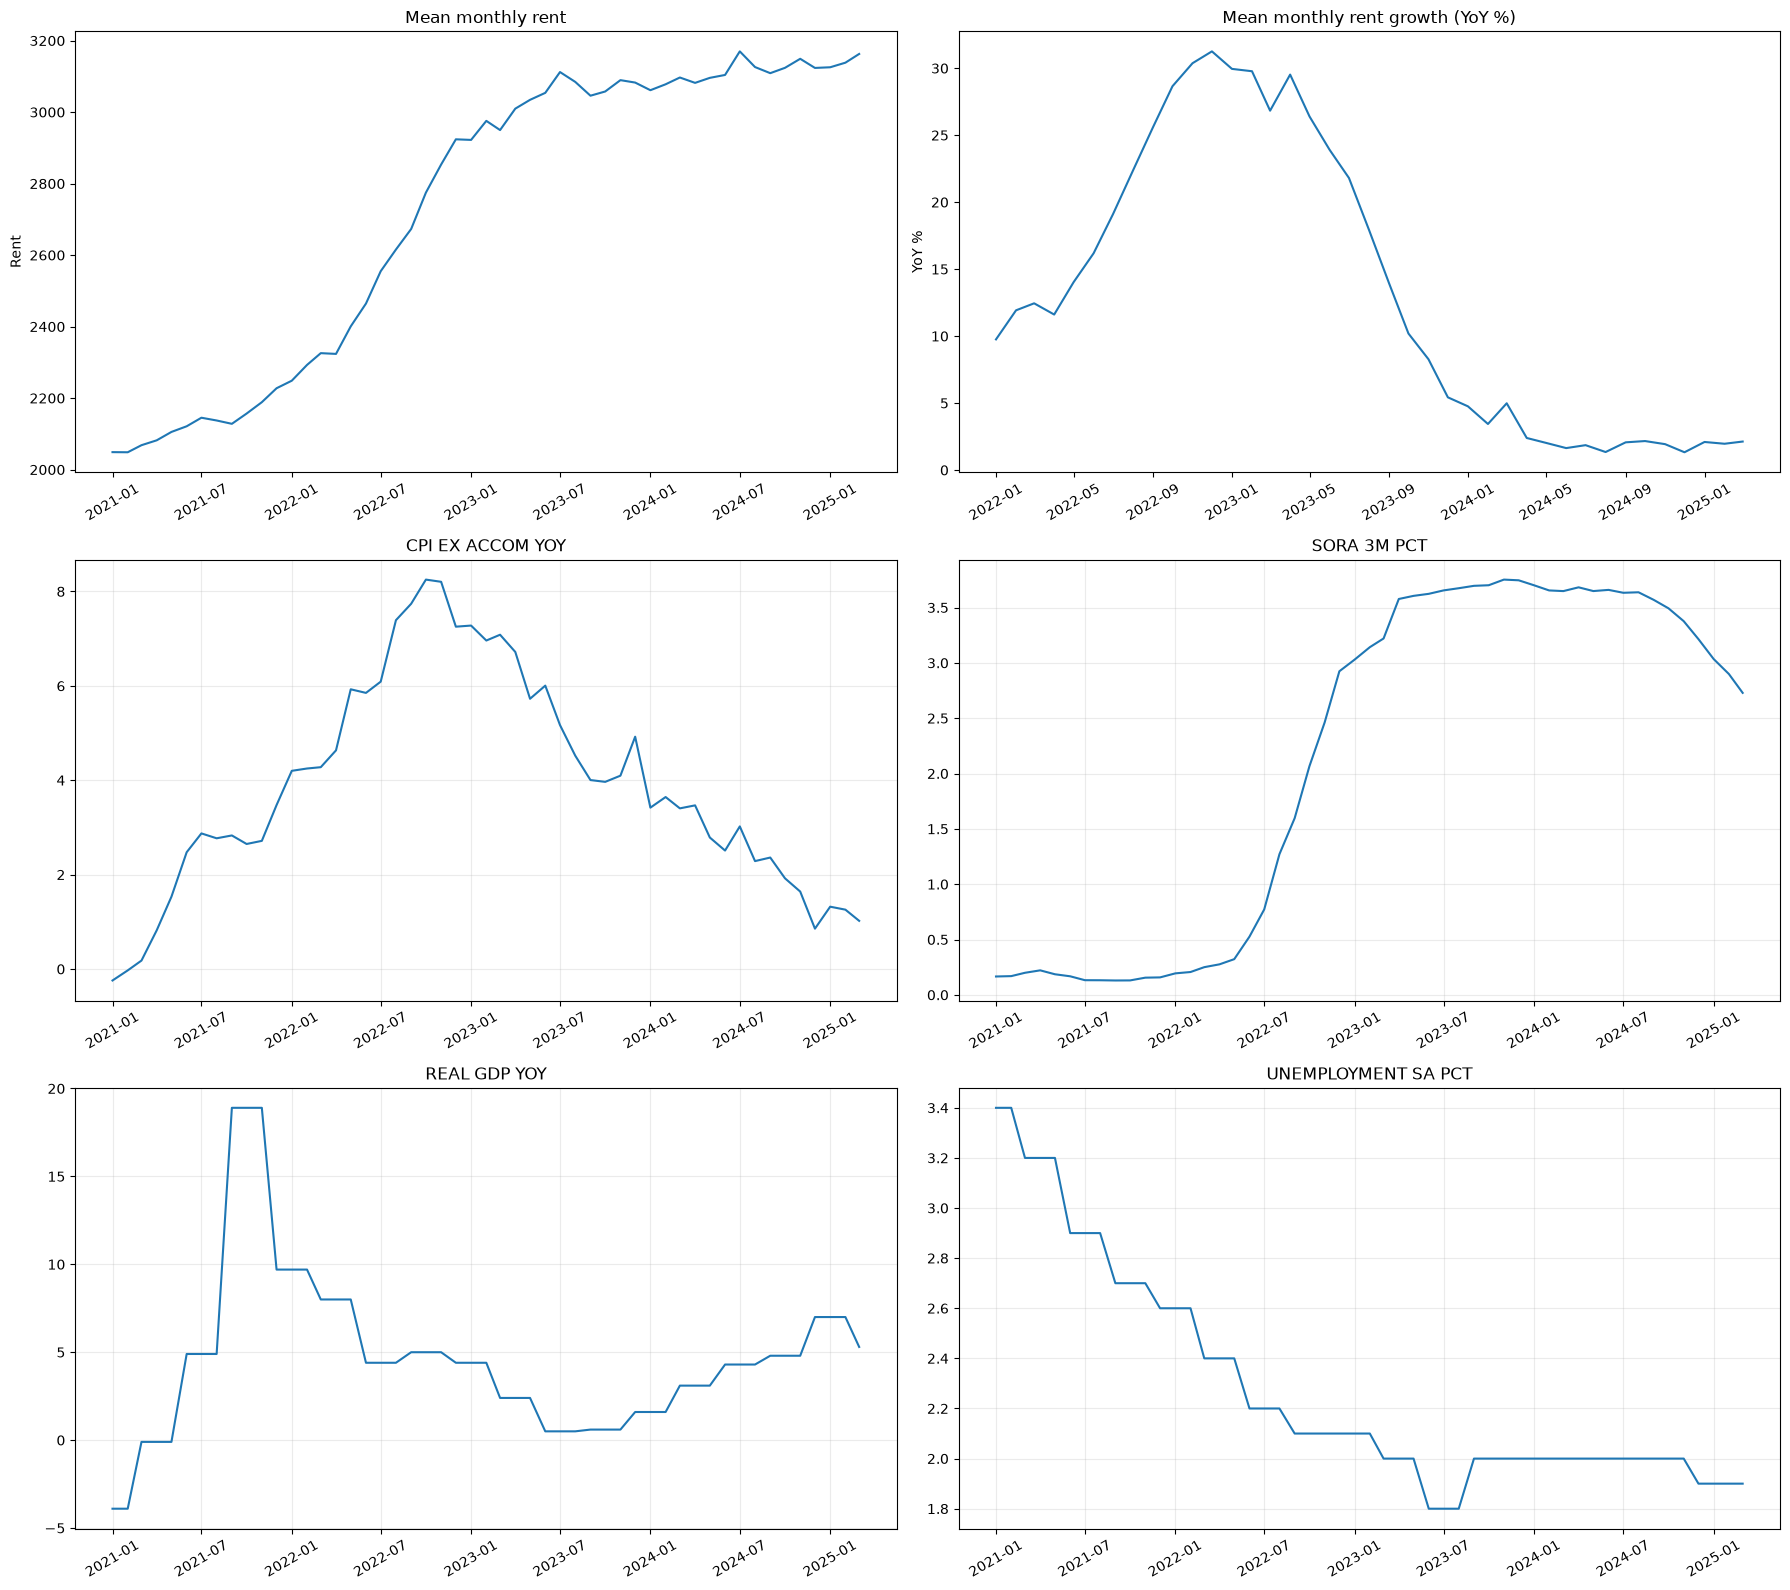

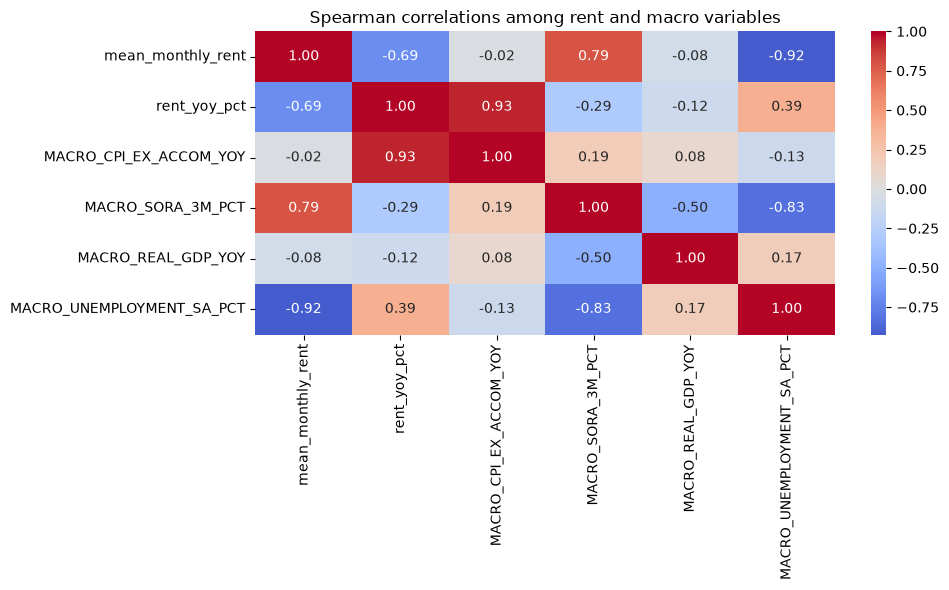

In [35]:
fig, axes = plt.subplots(3, 2, figsize=(18, 16))
axes[0, 0].plot(data['MONTH'], data['mean_monthly_rent'])
axes[0, 0].set_title('Mean monthly rent')
axes[0, 0].set_ylabel('Rent')
axes[0, 1].plot(data['MONTH'], data['rent_yoy_pct'])
axes[0, 1].set_title('Mean monthly rent growth (YoY %)')
axes[0, 1].set_ylabel('YoY %')
for ax, col in zip(axes.flat[2:], macro_cols):
    ax.plot(data['MONTH'], data[col])
    ax.set_title(col.replace('MACRO_', '').replace('_', ' '))
    ax.grid(alpha=0.25)
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

corr = data[['mean_monthly_rent', 'rent_yoy_pct'] + macro_cols].corr(method='spearman')
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Spearman correlations among rent and macro variables')
plt.tight_layout(); plt.show()


## 3. Create lagged predictors and chronological splits

Only lagged macro variables are used, ensuring that the model does not use the current month’s information when forecasting that month. The split is: training through 2023, validation during 2024, and a final untouched test period during 2025.

In [36]:
model_data = data.copy()
feature_cols = []
for col in macro_cols:
    for lag in (1, 3, 6, 12):
        name = f'{col}_lag{lag}'
        model_data[name] = model_data[col].shift(lag)
        feature_cols.append(name)
model_data = model_data.dropna(subset=feature_cols + ['mean_monthly_rent']).copy()

# Chronological windows for data available from Jan 2021 through Mar 2025.
# The 12-month lag construction means usable model rows begin in Jan 2022.
FIT_END = pd.Timestamp('2023-12-01')
VALID_END = pd.Timestamp('2024-12-01')
TEST_START = pd.Timestamp('2025-01-01')
TEST_END = pd.Timestamp('2025-03-01')
train = model_data[model_data['MONTH'] <= FIT_END]
valid = model_data[model_data['MONTH'].between(FIT_END + pd.offsets.MonthBegin(1), VALID_END)]
test = model_data[model_data['MONTH'].between(TEST_START, TEST_END)]
X_train, y_train = train[feature_cols], train['mean_monthly_rent']
X_valid, y_valid = valid[feature_cols], valid['mean_monthly_rent']
X_test, y_test = test[feature_cols], test['mean_monthly_rent']
print({name: len(frame) for name, frame in [('train', train), ('validation', valid), ('test', test)]})
print('Test month range:', test['MONTH'].min(), 'to', test['MONTH'].max(), '| unique months:', test['MONTH'].nunique())
if len(test) < 2:
    raise ValueError('Stage 1 test split has fewer than 2 observations; expand source date coverage or revise TEST_START.')


{'train': 24, 'validation': 12, 'test': 3}
Test month range: 2025-01-01 00:00:00 to 2025-03-01 00:00:00 | unique months: 3


## 4. Fit models and compare against baselines

LightGBM and Random Forest are retained as deliberately transparent machine-learning comparisons. A damped Holt exponential-smoothing model is then added as the preferred time-series alternative. The baselines are a previous-month forecast and a seasonal-naive forecast using the value from 12 months earlier.

The monthly series contains only a few dozen usable observations after constructing 12-month lags. This is too little data for high-capacity tree ensembles to learn stable nonlinear relationships: they can fit the training period while extrapolating poorly over the short holdout. Holt smoothing instead estimates only the current level and trend, applies exponentially decreasing weights to older observations, and damps the trend so that it does not grow unrealistically far beyond the observed range. This gives a parsimonious forecast that is aligned with the temporal structure of the target and does not require dozens of macro-feature coefficients.

In [37]:
lgbm_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15,
                           subsample=0.8, colsample_bytree=0.8,
                           objective='regression', random_state=42, verbosity=-1))
])
# With only a few dozen monthly observations, Holt is the preferred final
# forecast, while the ML models are retained to document their performance.
stage1_model = ExponentialSmoothing(
    train['mean_monthly_rent'].to_numpy(dtype=float),
    trend='add', damped_trend=True, initialization_method='estimated'
).fit(optimized=True)
forest = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=42))
])
lgbm_model.fit(X_train, y_train)
predictions = {'LightGBM': lgbm_model.predict(X_test),
              'Holt damped trend': stage1_model.forecast(len(test))}
forest.fit(X_train, y_train)
predictions['Random Forest'] = forest.predict(X_test)

test_indexed = model_data.set_index('MONTH')
test_months = test['MONTH']
predictions['Previous month'] = test_months.map(test_indexed['mean_monthly_rent'].shift(1)).to_numpy()
predictions['Same month previous year'] = test_months.map(test_indexed['mean_monthly_rent'].shift(12)).to_numpy()

def metrics(y_true, y_pred):
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    n = int(mask.sum())
    return {'N': n, 'MAE': mean_absolute_error(y_true[mask], y_pred[mask]),
            'RMSE': mean_squared_error(y_true[mask], y_pred[mask]) ** 0.5,
            'R2': r2_score(y_true[mask], y_pred[mask]) if n >= 2 else np.nan}

evaluation = pd.DataFrame({name: metrics(y_test.to_numpy(), pred) for name, pred in predictions.items()}).T
display(evaluation.sort_values('MAE'))


,N,MAE,RMSE,R2
Previous month,3.0,13.036342,15.964668,-0.067133
Holt damped trend,3.0,25.652238,25.901565,-1.808993
Same month previous year,3.0,63.498832,63.539739,-15.904001
Random Forest,3.0,227.489961,229.469435,-219.469424
LightGBM,3.0,355.897185,356.232569,-530.331935


### Holt exponential-smoothing forecast

The final Stage 1 forecast uses a damped Holt trend. It estimates a level and a trend from the short monthly rent series, exponentially downweights older observations, and dampens the trend for stable extrapolation.

,N,MAE,RMSE,R2
Validation,12.0,66.613750,72.447462,-5.073397
Test,3.0,9.517661,12.789614,0.315121


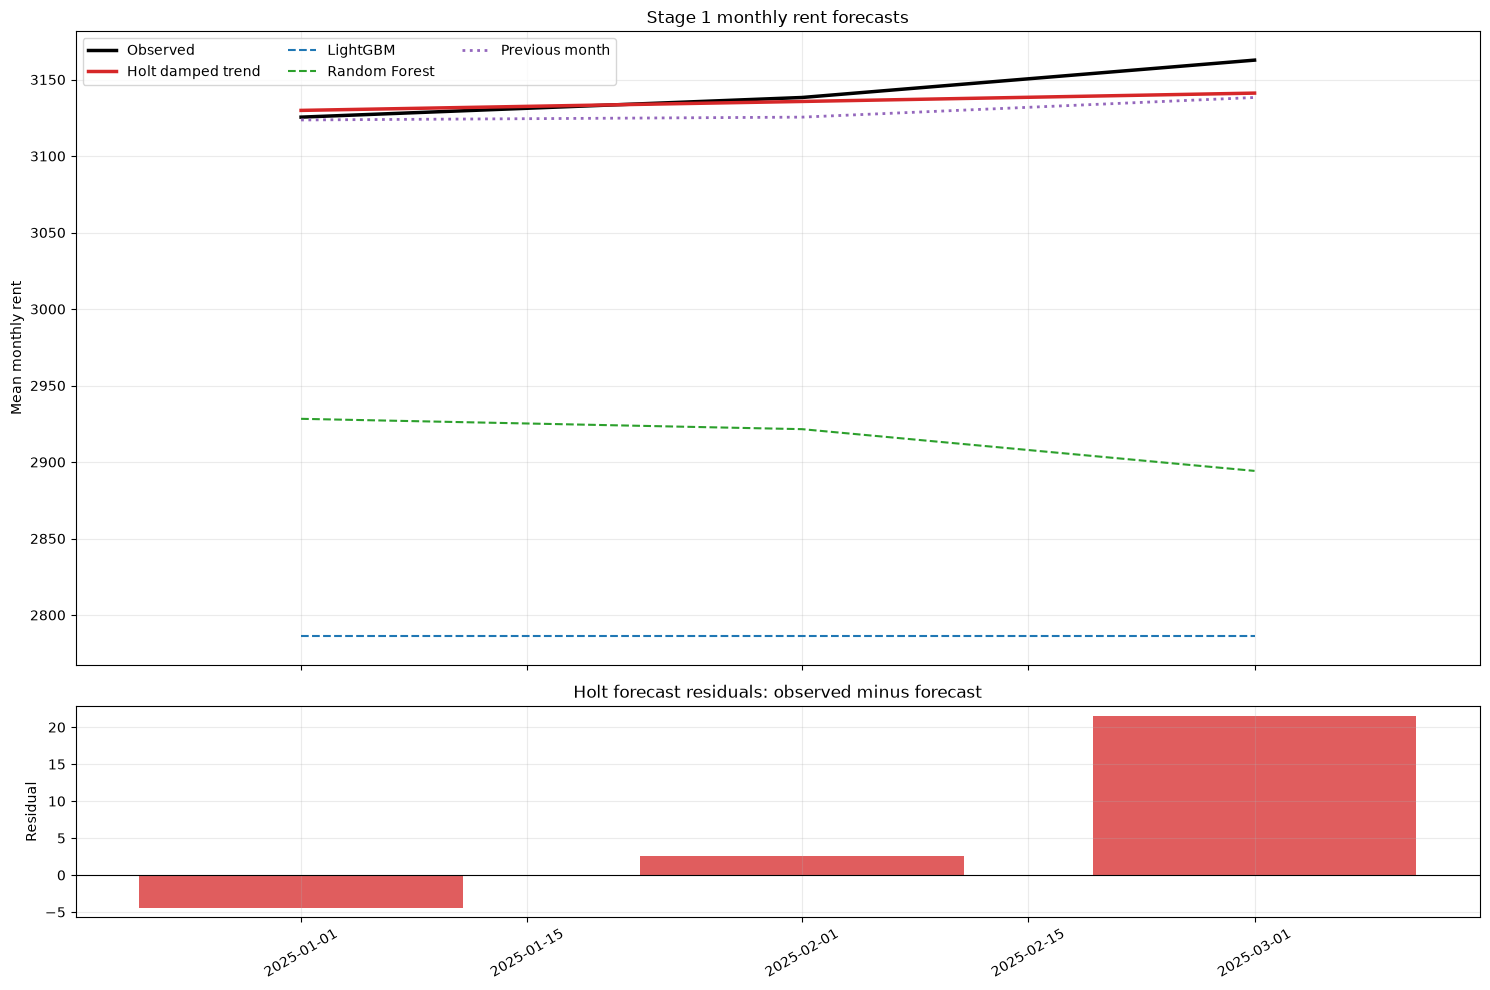

In [38]:
# Explicit Holt evaluation with chronological refits.
holt_fit_model = ExponentialSmoothing(
    train['mean_monthly_rent'].to_numpy(dtype=float),
    trend='add', damped_trend=True, initialization_method='estimated'
).fit(optimized=True)
holt_valid_prediction = holt_fit_model.forecast(len(valid))
holt_fit_valid_model = ExponentialSmoothing(
    pd.concat([train['mean_monthly_rent'], valid['mean_monthly_rent']]).to_numpy(dtype=float),
    trend='add', damped_trend=True, initialization_method='estimated'
).fit(optimized=True)
holt_test_prediction = holt_fit_valid_model.forecast(len(test))
holt_evaluation = pd.DataFrame({
    'Validation': metrics(y_valid.to_numpy(), holt_valid_prediction),
    'Test': metrics(y_test.to_numpy(), holt_test_prediction),
}).T
display(holt_evaluation)

# Holt is the Stage 1 forecast passed to Stage 2. In-sample fitted values
# are used for fit months; validation and test months use genuine forecasts.
holt_by_month = pd.concat([
    pd.Series(holt_fit_model.fittedvalues, index=train['MONTH']),
    pd.Series(holt_valid_prediction, index=valid['MONTH']),
    pd.Series(holt_test_prediction, index=test['MONTH']),
]).groupby(level=0).last()
stage1_monthly = model_data[['MONTH']].copy()
stage1_monthly['stage1_forecast'] = stage1_monthly['MONTH'].map(holt_by_month)

# Clear Stage 1 forecast chart.
chart = pd.DataFrame({'MONTH': test['MONTH'], 'Observed': y_test.to_numpy(),
                      'Holt damped trend': holt_test_prediction,
                      'LightGBM': predictions['LightGBM'],
                      'Random Forest': predictions['Random Forest'],
                      'Previous month': predictions['Previous month']})
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(chart['MONTH'], chart['Observed'], color='black', linewidth=2.5, label='Observed')
ax1.plot(chart['MONTH'], chart['Holt damped trend'], color='#d62728', linewidth=2.5, label='Holt damped trend')
ax1.plot(chart['MONTH'], chart['LightGBM'], color='#1f77b4', linestyle='--', label='LightGBM')
ax1.plot(chart['MONTH'], chart['Random Forest'], color='#2ca02c', linestyle='--', label='Random Forest')
ax1.plot(chart['MONTH'], chart['Previous month'], color='#9467bd', linestyle=':', linewidth=2, label='Previous month')
ax1.set_title('Stage 1 monthly rent forecasts')
ax1.set_ylabel('Mean monthly rent')
ax1.legend(ncol=3, frameon=True)
ax1.grid(alpha=.25)
ax2.axhline(0, color='black', linewidth=.8)
ax2.bar(chart['MONTH'], chart['Observed'] - chart['Holt damped trend'], width=20, color='#d62728', alpha=.75)
ax2.set_title('Holt forecast residuals: observed minus forecast')
ax2.set_ylabel('Residual')
ax2.grid(alpha=.25)
plt.xticks(rotation=30); plt.tight_layout(); plt.show()


## 5. Evaluate forecasts visually

The final test period is plotted against the observed monthly mean rent. A useful model should track turning points and should outperform both simple baselines, especially the seasonal-naive forecast.

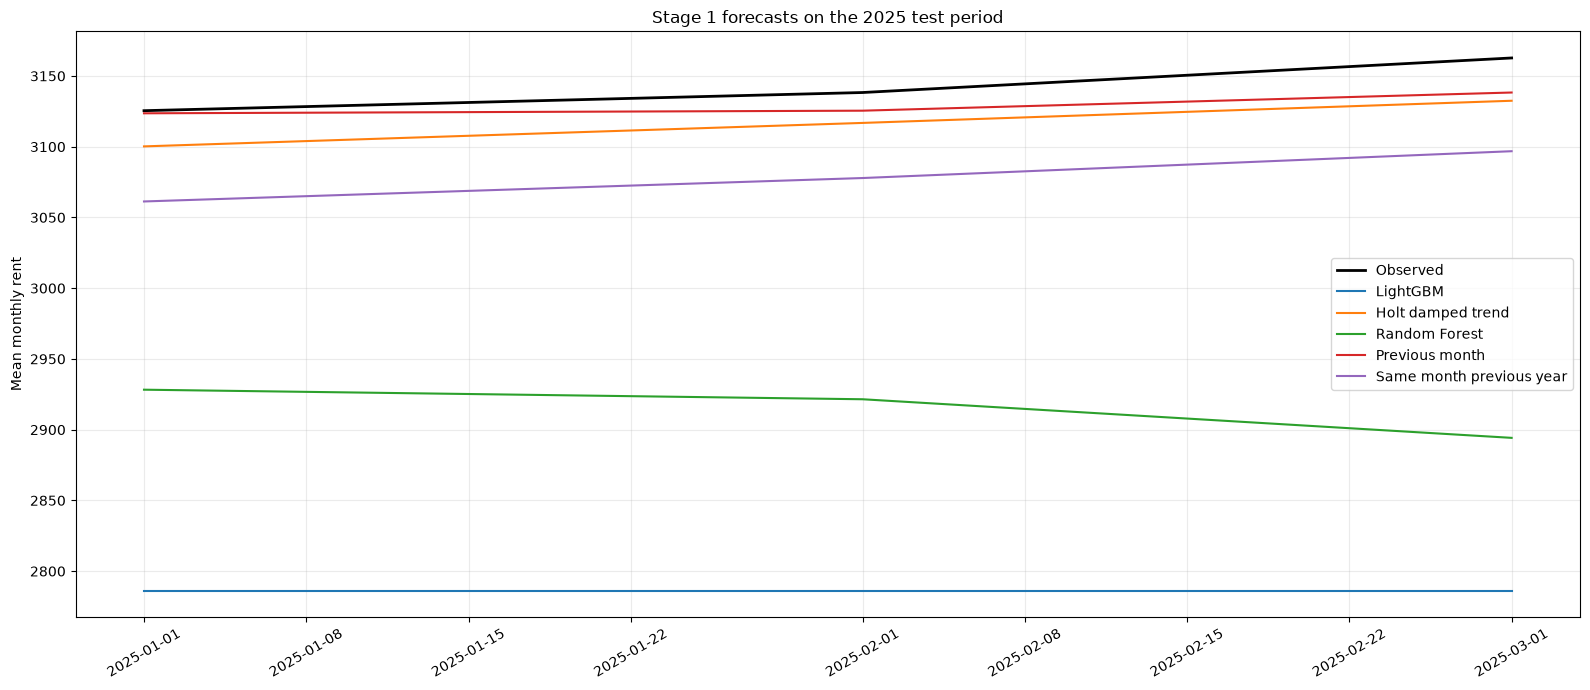

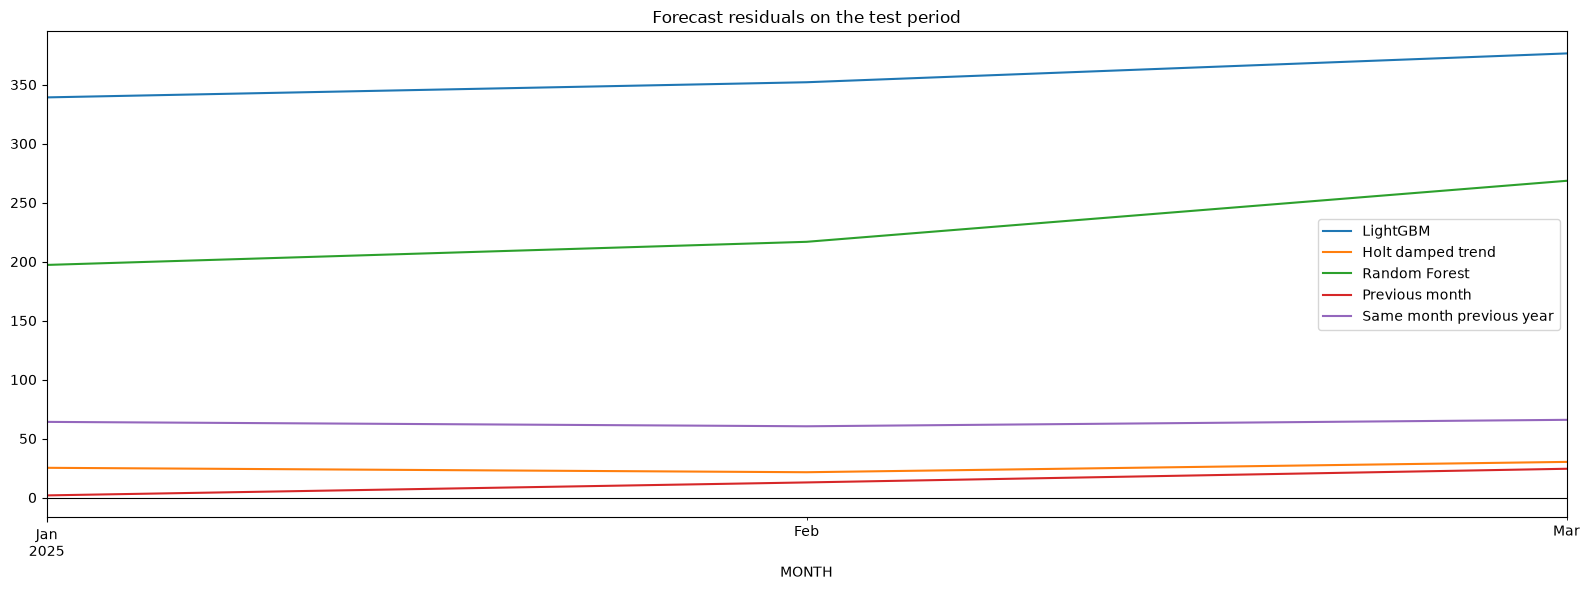

In [39]:
fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(test['MONTH'], y_test, color='black', linewidth=2, label='Observed')
for name, pred in predictions.items():
    ax.plot(test['MONTH'], pred, linewidth=1.5, label=name)
ax.set_title('Stage 1 forecasts on the 2025 test period')
ax.set_ylabel('Mean monthly rent')
ax.legend()
ax.grid(alpha=0.25)
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

residuals = pd.DataFrame({'MONTH': test['MONTH'], **{name: y_test.to_numpy() - pred for name, pred in predictions.items()}})
residuals.set_index('MONTH').plot(figsize=(16, 6), title='Forecast residuals on the test period')
plt.axhline(0, color='black', linewidth=0.8); plt.tight_layout(); plt.show()


## 6. Interpretation and hand-off to Stage 2

The preferred Stage 1 model should be selected using validation performance, not the test set. The test set is used once for the final report. The resulting monthly forecast can be joined back to individual property records by month and supplied to Stage 2 as a market-level feature.

Because the dataset contains only a small number of monthly observations, complex models should be treated cautiously. If the macro models do not beat the seasonal-naive baseline, macroeconomic variables may add limited short-horizon forecasting value; Stage 2 should still evaluate whether the forecast improves individual-property predictions.

# Stage 2 — Property-level residual modelling

Two separate pipelines are evaluated: (1) Holt Stage 1 → XGBoost Stage 2 and (2) Random Forest Stage 1 → XGBoost Stage 2. Each Stage 2 model predicts the residual `observed rent - its own Stage 1 forecast`; Stage 2 also includes accessibility features from `hdb_features_with_accessibility.csv`. The final prediction is the sum of the corresponding two stages.

XGBoost is used after one-hot encoding and mutual-information feature selection, allowing the experiment to use a consistent numeric feature matrix while modelling nonlinear residual effects.

In [40]:
from xgboost import XGBRegressor
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.model_selection import ParameterGrid
TARGET = 'MONTHLY_RENT'
import pyarrow as pa

TRAIN_PARQUET = ROOT / 'data' / 'original_dataset' / 'train.parquet'
if not TRAIN_PARQUET.exists():
    TRAIN_PARQUET = ROOT / 'data' / 'train_features.parquet'
if not TRAIN_PARQUET.exists():
    raise FileNotFoundError('Could not find train.parquet or train_features.parquet under the project data directory.')
if hasattr(pa, 'PyExtensionType') and hasattr(pa.PyExtensionType, 'set_auto_load'):
    pa.PyExtensionType.set_auto_load(True)
property_df = pd.read_parquet(TRAIN_PARQUET, engine='pyarrow')
property_date = 'RENT_APPROVAL_DATE' if 'RENT_APPROVAL_DATE' in property_df else 'approval_date'
property_df[property_date] = pd.to_datetime(property_df[property_date])
property_df['MONTH'] = property_df[property_date].dt.to_period('M').dt.to_timestamp()

# Stage 1: only the four original macro variables and their lagged versions.
# stage1_monthly contains the Holt Stage 1 forecast. Add a parallel
# Random Forest Stage 1 forecast for the second residual pipeline.
stage1_monthly['stage1_rf_forecast'] = forest.predict(model_data[feature_cols])
property_df = property_df.merge(stage1_monthly, on='MONTH', how='inner')

# Stage 2 accessibility enrichment from the requested source file.
access = pd.read_csv(access_path)
access_cols = ['ADDRESS_KEY', 'MRT_DISTANCE_KM', 'BUS_STOP_DISTANCE_KM', 'MRT_WITHIN_250M', 'BUS_STOPS_WITHIN_250M', 'MRT_WITHIN_750M', 'BUS_STOPS_WITHIN_750M', 'SCHOOL_DISTANCE_KM', 'mean_travel_time_min', 'median_travel_time_min', 'cbd_travel_time_min', 'regional_hub_travel_time_min', 'essential_services_time_min', 'education_access_time_min', 'ACCESSIBILITY_SCORE']
access = access[[c for c in access_cols if c in access.columns]].drop_duplicates('ADDRESS_KEY')
property_df = property_df.merge(access, on='ADDRESS_KEY', how='left')
property_df['stage1_residual'] = property_df[TARGET] - property_df['stage1_forecast']

fit_mask = property_df['MONTH'] <= FIT_END
valid_mask = property_df['MONTH'].between(FIT_END + pd.offsets.MonthBegin(1), VALID_END)
test_mask = property_df['MONTH'].between(TEST_START, TEST_END)
property_df['stage1_rf_residual'] = property_df[TARGET] - property_df['stage1_rf_forecast']
excluded = {TARGET, 'stage1_forecast', 'stage1_rf_forecast', 'stage1_residual', 'stage1_rf_residual', 'MONTH', property_date, 'ADDRESS_KEY'}
stage2_feature_cols = [c for c in property_df.columns if c not in excluded and not c.lower().startswith(('macro_', 'coe_', 'stock_')) and not pd.api.types.is_datetime64_any_dtype(property_df[c])]
X = pd.get_dummies(property_df[stage2_feature_cols], dummy_na=True)
X = X.replace([np.inf, -np.inf], np.nan).fillna(-999)
X_fit, X_valid, X_test = X.loc[fit_mask], X.loc[valid_mask], X.loc[test_mask]
y_fit = property_df.loc[fit_mask, 'stage1_residual']
y_valid = property_df.loc[valid_mask, 'stage1_residual']
print(f'Rows: fit={len(X_fit):,}, validation={len(X_valid):,}, test={len(X_test):,}')
print(f'Candidate encoded Stage 2 features before selection: {X.shape[1]:,}')
print('Accessibility features added:', [c for c in access_cols if c in property_df.columns])


Rows: fit=68,218, validation=35,239, test=8,924
Candidate encoded Stage 2 features before selection: 12,971
Accessibility features added: ['ADDRESS_KEY', 'MRT_DISTANCE_KM', 'BUS_STOP_DISTANCE_KM', 'MRT_WITHIN_250M', 'BUS_STOPS_WITHIN_250M', 'MRT_WITHIN_750M', 'BUS_STOPS_WITHIN_750M', 'SCHOOL_DISTANCE_KM', 'mean_travel_time_min', 'median_travel_time_min', 'cbd_travel_time_min', 'regional_hub_travel_time_min', 'essential_services_time_min', 'education_access_time_min', 'ACCESSIBILITY_SCORE']


## Stage 2 training and evaluation

The residual model uses only Jan 2021–Mar 2024 for fitting, Apr 2024–Feb 2025 for validation and Mar 2025–Jul 2026 for final testing. A baseline XGBoost model is compared with a small validation-driven hyperparameter search before the selected model is refit on 2023–2024.

In [58]:
# Feature selection happens before fitting XGBoost and is learned from 2023 only.
k = min(100, X_fit.shape[1])
selector = SelectKBest(mutual_info_regression, k=k)
X_fit_selected = selector.fit_transform(X_fit, y_fit)
X_valid_selected = selector.transform(X_valid)
X_test_selected = selector.transform(X_test)
selected_features = X.columns[selector.get_support()].tolist()
print(f'Selected {len(selected_features)} of {X.shape[1]} encoded features')

def make_xgb(params=None):
    base = dict(n_estimators=800, max_depth=6, learning_rate=.05,
                subsample=.8, colsample_bytree=.8, objective='reg:squarederror',
                eval_metric='mae', random_state=42, n_jobs=-1)
    if params: base.update(params)
    return XGBRegressor(**base)

baseline_model = make_xgb()
baseline_model.fit(X_fit_selected, y_fit, eval_set=[(X_valid_selected, y_valid)], verbose=False)
baseline_valid_residual = baseline_model.predict(X_valid_selected)

tuning_grid = list(ParameterGrid({'max_depth': [3, 6], 'learning_rate': [.03, .07], 'min_child_weight': [1, 5]}))
tuning_rows = []
for params in tuning_grid:
    candidate = make_xgb(params)
    candidate.fit(X_fit_selected, y_fit, eval_set=[(X_valid_selected, y_valid)], verbose=False)
    pred = candidate.predict(X_valid_selected)
    tuning_rows.append({'params': params, 'MAE': mean_absolute_error(y_valid, pred), 'RMSE': mean_squared_error(y_valid, pred) ** .5})
tuning_results = pd.DataFrame(tuning_rows).sort_values('MAE')
display(tuning_results)
best_params = tuning_results.iloc[0]['params']
residual_model = make_xgb(best_params)
X_fit_valid = np.vstack([X_fit_selected, X_valid_selected])
y_fit_valid = pd.concat([y_fit, y_valid])
residual_model.fit(X_fit_valid, y_fit_valid, verbose=False)

def score(y_true, prediction):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    prediction = np.asarray(prediction, dtype=float).reshape(-1)
    mask = np.isfinite(y_true) & np.isfinite(prediction)
    n = int(mask.sum())
    return {'N': n,
            'MAE': float(mean_absolute_error(y_true[mask], prediction[mask])),
            'RMSE': float(mean_squared_error(y_true[mask], prediction[mask]) ** .5),
            'R2': float(r2_score(y_true[mask], prediction[mask])) if n >= 2 else np.nan}

def evaluate(mask, X_part):
    stage1 = property_df.loc[mask, 'stage1_forecast'].to_numpy()
    actual = property_df.loc[mask, TARGET].to_numpy()
    corrected = stage1 + residual_model.predict(X_part)
    return score(actual, stage1), score(actual, corrected), actual, stage1, corrected

valid_stage1, valid_stage2, valid_actual, valid_base, valid_corrected = evaluate(valid_mask, X_valid_selected)
test_stage1, test_stage2, test_actual, test_base, test_corrected = evaluate(test_mask, X_test_selected)
# Preserve the Holt Stage 2 metrics; the submission cell uses a different
# variable for encoded test features.
holt_stage2_test_metrics = test_stage2.copy()
evaluation = pd.DataFrame({'Stage 1 validation': valid_stage1, 'Stage 2 validation': valid_stage2, 'Stage 1 test': test_stage1, 'Stage 2 test': test_stage2}).T
display(evaluation)


Selected 100 of 12971 encoded features


,params,MAE,RMSE
1,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",418.724753,565.841363
0,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",419.479845,567.253415
4,"{'learning_rate': 0.07, 'max_depth': 3, 'min_c...",422.416452,570.465387
5,"{'learning_rate': 0.07, 'max_depth': 3, 'min_c...",423.608762,571.953540
2,"{'learning_rate': 0.03, 'max_depth': 6, 'min_c...",430.349742,577.959989
3,"{'learning_rate': 0.03, 'max_depth': 6, 'min_c...",436.387715,583.596409
6,"{'learning_rate': 0.07, 'max_depth': 6, 'min_c...",445.616147,593.105721
7,"{'learning_rate': 0.07, 'max_depth': 6, 'min_c...",455.338594,604.765898


,N,MAE,RMSE,R2
Stage 1 validation,35239.0,516.387802,672.351728,-0.009368
Stage 2 validation,35239.0,358.334368,484.454153,0.475963
Stage 1 test,8924.0,494.247984,647.314666,0.000172
Stage 2 test,8924.0,352.583536,465.024277,0.484005


## Stage 2 comparison: Random Forest Stage 1 residuals

This is a separate two-stage pipeline. Its Stage 1 forecast comes from Random Forest, and its Stage 2 XGBoost model is trained on `observed rent - Random Forest forecast`. It is evaluated beside the Holt-residual pipeline above.

In [59]:
# Select residual features independently for the Random Forest Stage 1 pipeline.
y_fit_rf = property_df.loc[fit_mask, 'stage1_rf_residual']
y_valid_rf = property_df.loc[valid_mask, 'stage1_rf_residual']
selector_rf = SelectKBest(mutual_info_regression, k=min(100, X_fit.shape[1]))
X_fit_rf = selector_rf.fit_transform(X_fit, y_fit_rf)
X_valid_rf = selector_rf.transform(X_valid)
X_test_rf = selector_rf.transform(X_test)

rf_residual_tuning = []
for params in tuning_grid:
    candidate = make_xgb(params)
    candidate.fit(X_fit_rf, y_fit_rf, eval_set=[(X_valid_rf, y_valid_rf)], verbose=False)
    pred = candidate.predict(X_valid_rf)
    rf_residual_tuning.append({'params': params, 'MAE': mean_absolute_error(y_valid_rf, pred), 'RMSE': mean_squared_error(y_valid_rf, pred) ** .5})
rf_best_params = pd.DataFrame(rf_residual_tuning).sort_values('MAE').iloc[0]['params']
rf_residual_model = make_xgb(rf_best_params)
rf_residual_model.fit(np.vstack([X_fit_rf, X_valid_rf]), pd.concat([y_fit_rf, y_valid_rf]), verbose=False)

rf_stage1_valid = property_df.loc[valid_mask, 'stage1_rf_forecast'].to_numpy()
rf_stage1_test = property_df.loc[test_mask, 'stage1_rf_forecast'].to_numpy()
rf_stage2_valid_pred = rf_stage1_valid + rf_residual_model.predict(X_valid_rf)
rf_stage2_test_pred = rf_stage1_test + rf_residual_model.predict(X_test_rf)
rf_pipeline_evaluation = pd.DataFrame({
    'RF Stage 1 validation': score(property_df.loc[valid_mask, TARGET], rf_stage1_valid),
    'RF Stage 2 validation': score(property_df.loc[valid_mask, TARGET], rf_stage2_valid_pred),
    'RF Stage 1 test': score(property_df.loc[test_mask, TARGET], rf_stage1_test),
    'RF Stage 2 test': score(property_df.loc[test_mask, TARGET], rf_stage2_test_pred),
}).T
display(rf_pipeline_evaluation)

def comparison_row(label, result):
    result = dict(result)
    return {'Pipeline': label, 'N': int(result.get('N', 0)),
            'MAE': float(result['MAE']), 'RMSE': float(result['RMSE']),
            'R2': float(result['R2']) if pd.notna(result.get('R2')) else np.nan}

pipeline_comparison = pd.DataFrame([
    comparison_row('Holt Stage 1 → XGBoost Stage 2 validation', valid_stage2),
    comparison_row('Holt Stage 1 → XGBoost Stage 2 test', holt_stage2_test_metrics),
    comparison_row('Random Forest Stage 1 → XGBoost Stage 2 validation', rf_pipeline_evaluation.loc['RF Stage 2 validation']),
    comparison_row('Random Forest Stage 1 → XGBoost Stage 2 test', rf_pipeline_evaluation.loc['RF Stage 2 test']),
]).set_index('Pipeline')
display(pipeline_comparison)

,N,MAE,RMSE,R2
RF Stage 1 validation,35239.0,527.772169,683.647627,-0.043569
RF Stage 2 validation,35239.0,358.983121,484.538634,0.475780
RF Stage 1 test,8924.0,533.004288,686.849683,-0.125688
RF Stage 2 test,8924.0,329.914152,457.363366,0.500866


,N,MAE,RMSE,R2
Pipeline,,,,
Holt Stage 1 → XGBoost Stage 2 validation,35239,358.334368,484.454153,0.475963
Holt Stage 1 → XGBoost Stage 2 test,8924,352.583536,465.024277,0.484005
Random Forest Stage 1 → XGBoost Stage 2 validation,35239,358.983121,484.538634,0.475780
Random Forest Stage 1 → XGBoost Stage 2 test,8924,329.914152,457.363366,0.500866


In [ ]:
# Lightweight output-only view; this cell does not retrain the models.
rf_test_output = rf_pipeline_evaluation.loc[
    ['RF Stage 1 test', 'RF Stage 2 test'], ['N', 'MAE', 'RMSE', 'R2']
].copy()
display(rf_test_output.style.format({'MAE': '{:,.2f}', 'RMSE': '{:,.2f}', 'R2': '{:.4f}'}))

## Stage 2 diagnostics and feature importance

The forecast plot shows whether residual correction improves the market-only forecast. Feature importance identifies which property and accessibility variables are most useful for explaining deviations from macroeconomic market conditions. Importance is associative rather than causal.

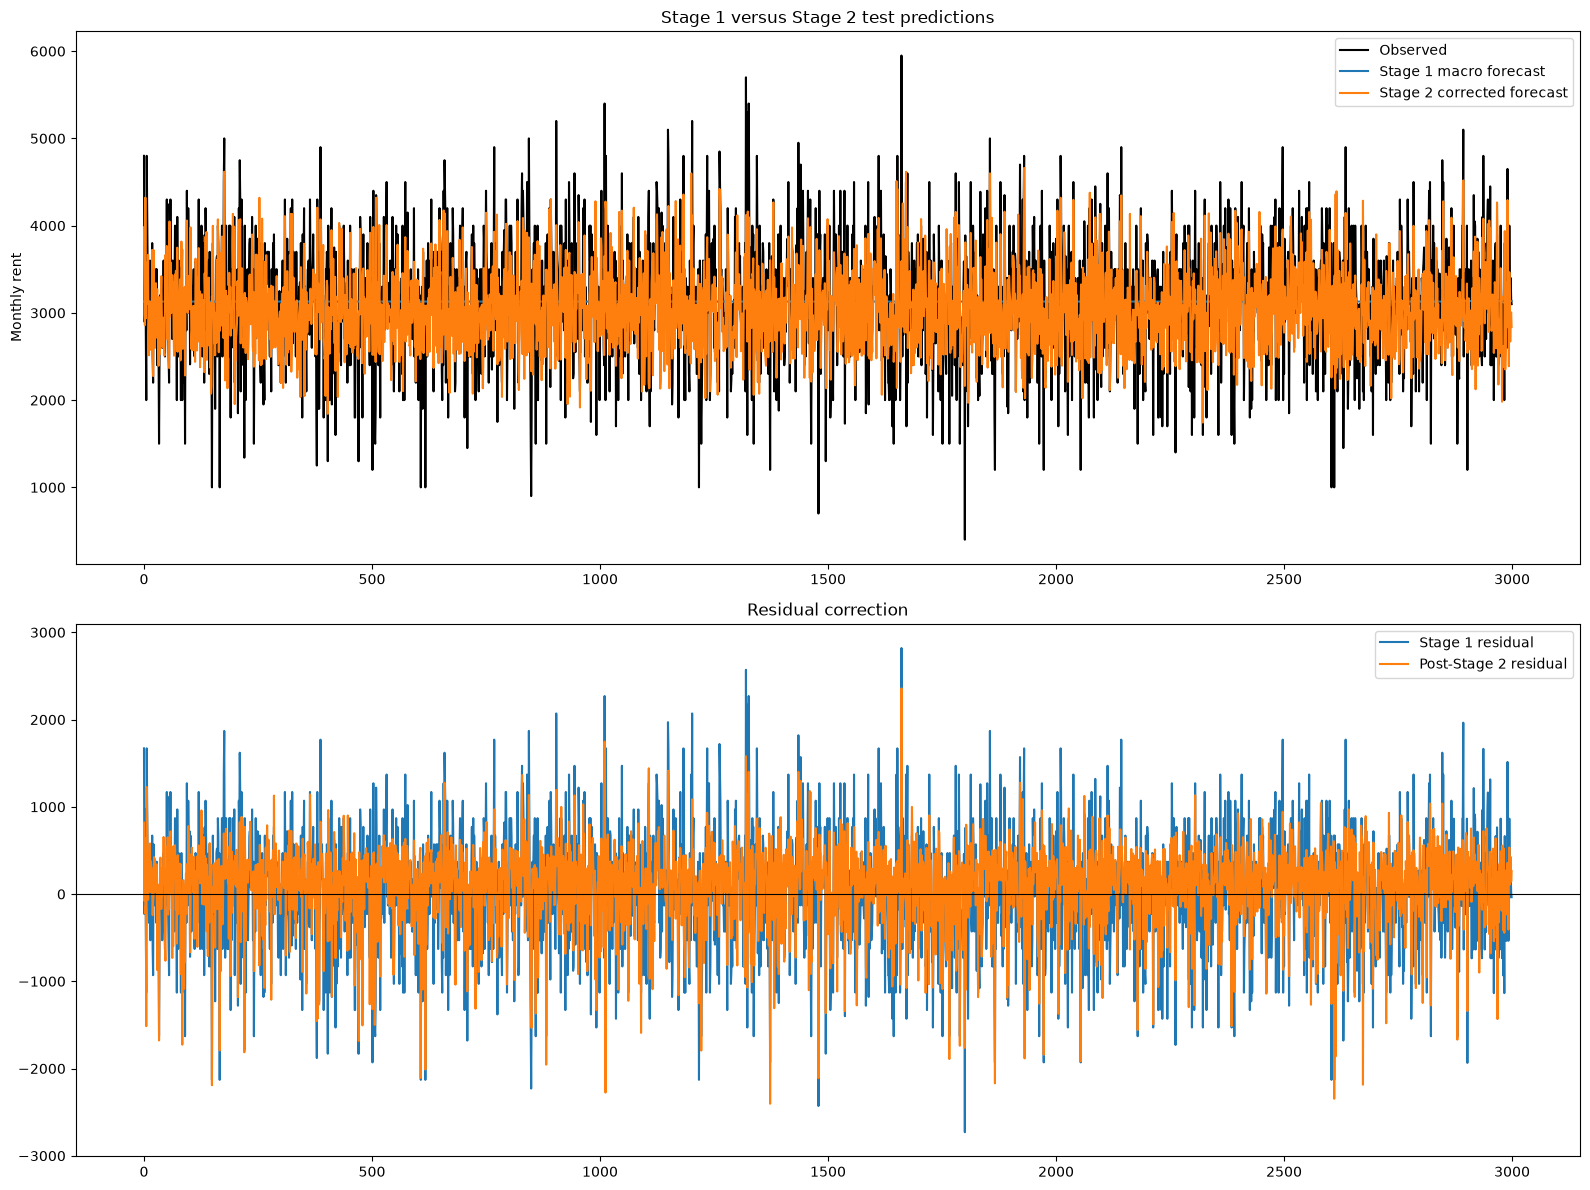

,feature,importance
80,FLAT_TYPE_3-room,0.323793
99,REGION_central region,0.141134
45,PA_PCT_AGE_15_64,0.072884
52,PA_AVG_HOUSEHOLD_SIZE,0.045795
79,FLAT_TYPE_2-room,0.042384
1,FLOOR_AREA_SQM,0.037329
11,LATITUDE,0.030357
63,ADDRESS_PRIOR_MEDIAN,0.025556
3,RENT_YEAR,0.022673
81,FLAT_TYPE_4-room,0.019358


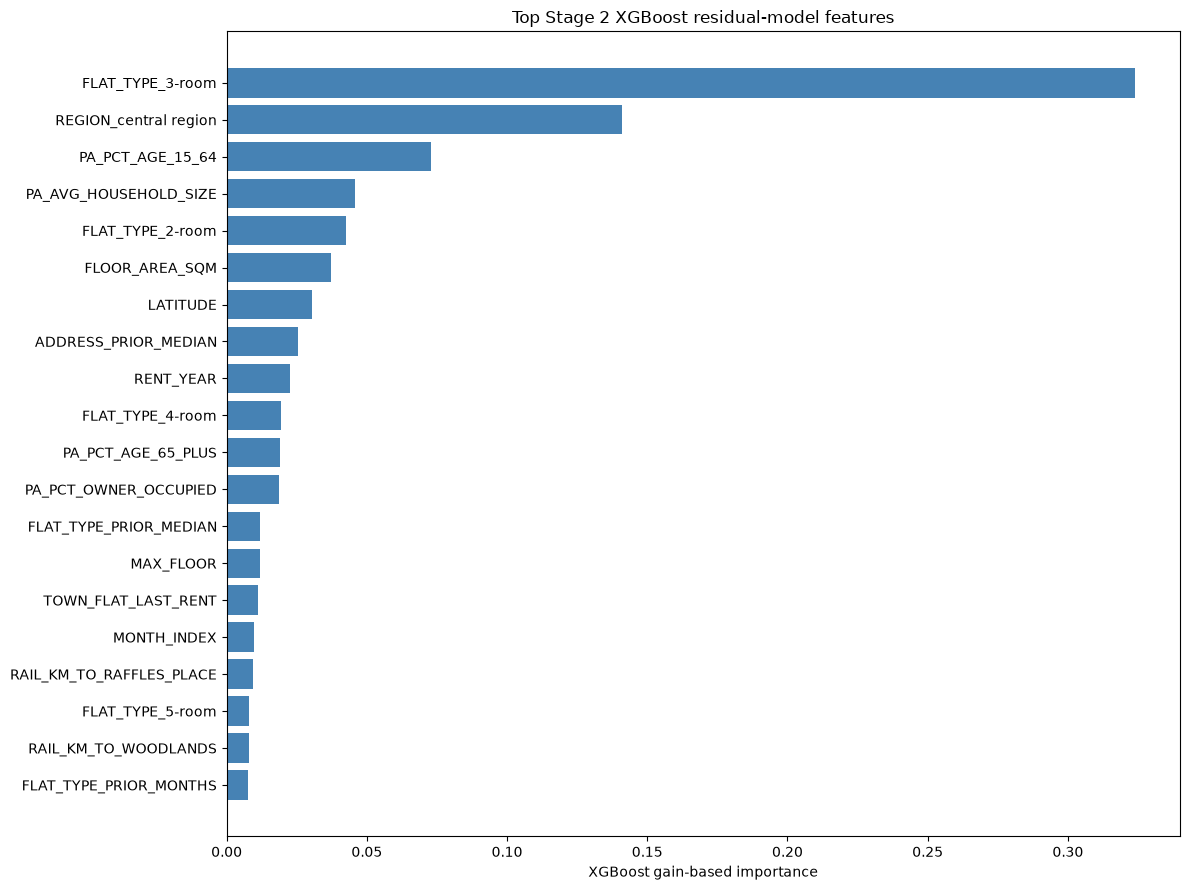

In [60]:
plot_n = min(len(test_actual), 3000)
fig, axes = plt.subplots(2, 1, figsize=(16, 12))
axes[0].plot(test_actual[:plot_n], color='black', label='Observed')
axes[0].plot(test_base[:plot_n], label='Stage 1 macro forecast')
axes[0].plot(test_corrected[:plot_n], label='Stage 2 corrected forecast')
axes[0].set_title('Stage 1 versus Stage 2 test predictions'); axes[0].set_ylabel('Monthly rent'); axes[0].legend()
axes[1].plot(test_actual[:plot_n] - test_base[:plot_n], label='Stage 1 residual')
axes[1].plot(test_actual[:plot_n] - test_corrected[:plot_n], label='Post-Stage 2 residual')
axes[1].axhline(0, color='black', linewidth=.8); axes[1].set_title('Residual correction'); axes[1].legend()
plt.tight_layout(); plt.show()

importance = pd.DataFrame({'feature': selected_features, 'importance': residual_model.feature_importances_}).sort_values('importance', ascending=False)
display(importance.head(25))
top = importance.head(20).sort_values('importance')
plt.figure(figsize=(12, 9)); plt.barh(top['feature'], top['importance'], color='steelblue')
plt.title('Top Stage 2 XGBoost residual-model features'); plt.xlabel('XGBoost gain-based importance')
plt.tight_layout(); plt.show()


## 7. Write the competition submission

The competition submission must contain the original test-row identifier and one finite prediction per test row, in original test order.

In [61]:
# Build the official test predictions using the fitted Stage 1 and Stage 2 models.
TEST_PARQUET = ROOT / 'data' / 'original_dataset' / 'test.parquet'
if not TEST_PARQUET.exists():
    TEST_PARQUET = ROOT / 'data' / 'test_features.parquet'
test_property = pd.read_parquet(TEST_PARQUET, engine='pyarrow')
assert 'ROW_ID' in test_property, 'Test features must retain the original ROW_ID.'
test_property = test_property.copy()
test_property[property_date] = pd.to_datetime(test_property[property_date])
test_property['MONTH'] = test_property[property_date].dt.to_period('M').dt.to_timestamp()
test_property = test_property.sort_values('ROW_ID').reset_index(drop=True)

# Apply the same market forecast and accessibility enrichment used for training.
test_property = test_property.merge(stage1_monthly, on='MONTH', how='left', validate='many_to_one')
# Future test months may not occur in the historical rent table. Forecast
# them from the full observed monthly rent history with damped Holt trend.
missing_stage1 = test_property['stage1_forecast'].isna()
if missing_stage1.any():
    full_holt = ExponentialSmoothing(
        monthly_rent['mean_monthly_rent'].to_numpy(dtype=float),
        trend='add', damped_trend=True, initialization_method='estimated'
    ).fit(optimized=True)
    observed_last_month = monthly_rent['MONTH'].max()
    future_months = sorted(test_property.loc[missing_stage1, 'MONTH'].unique())
    horizon = max(1, (max(future_months).year - observed_last_month.year) * 12 + max(future_months).month - observed_last_month.month)
    future_forecast = pd.Series(full_holt.forecast(horizon), index=pd.date_range(observed_last_month + pd.offsets.MonthBegin(1), periods=horizon, freq='MS'))
    test_property.loc[missing_stage1, 'stage1_forecast'] = test_property.loc[missing_stage1, 'MONTH'].map(future_forecast)
test_property['stage1_forecast'] = test_property['stage1_forecast'].fillna(monthly_rent['mean_monthly_rent'].iloc[-1])
missing_rf_stage1 = test_property['stage1_rf_forecast'].isna()
if missing_rf_stage1.any() and set(feature_cols).issubset(test_property.columns):
    test_property.loc[missing_rf_stage1, 'stage1_rf_forecast'] = forest.predict(test_property.loc[missing_rf_stage1, feature_cols])
test_property['stage1_rf_forecast'] = test_property['stage1_rf_forecast'].fillna(stage1_monthly['stage1_rf_forecast'].dropna().iloc[-1])
test_property = test_property.merge(access, on='ADDRESS_KEY', how='left', validate='many_to_one')
assert test_property['stage1_forecast'].notna().all(), 'Missing Stage 1 forecast after fallback.'

test_stage2_features = pd.get_dummies(test_property[stage2_feature_cols], dummy_na=True)
test_stage2_features = test_stage2_features.reindex(columns=X.columns, fill_value=0)
test_stage2_features = test_stage2_features.replace([np.inf, -np.inf], np.nan).fillna(-999)
test_stage2_selected = selector.transform(test_stage2_features)
test_prediction = test_property['stage1_forecast'].to_numpy() + residual_model.predict(test_stage2_selected)

# Separate competition submission: Random Forest Stage 1 → XGBoost Stage 2.
rf_test_stage2_selected = selector_rf.transform(test_stage2_features)
rf_test_prediction = (
    test_property['stage1_rf_forecast'].to_numpy()
    + rf_residual_model.predict(rf_test_stage2_selected)
)

submission = pd.DataFrame({
    'Id': test_property['ROW_ID'].astype(int),
    'Predicted': test_prediction.astype(float),
})
assert len(submission) == 50_000, f'Expected 50,000 submission rows, got {len(submission):,}.'
assert submission['Id'].equals(pd.Series(np.arange(50_000), name='Id')), 'IDs are not in required original order.'
assert submission['Predicted'].notna().all() and np.isfinite(submission['Predicted']).all()
submission_path = Path.cwd() / 'submission_time_series_plus_residual.csv'
submission.to_csv(submission_path, index=False)

rf_submission = pd.DataFrame({
    'Id': test_property['ROW_ID'].astype(int),
    'Predicted': rf_test_prediction.astype(float),
})
assert len(rf_submission) == 50_000
assert rf_submission['Id'].equals(pd.Series(np.arange(50_000), name='Id'))
assert rf_submission['Predicted'].notna().all() and np.isfinite(rf_submission['Predicted']).all()
rf_submission_path = Path.cwd() / 'submission_random_forest_stage1_xgboost_stage2.csv'
rf_submission.to_csv(rf_submission_path, index=False)
print(f'Wrote Holt submission: {submission_path} with shape {submission.shape}')
print(f'Wrote RF Stage 1 → XGBoost Stage 2 submission: {rf_submission_path} with shape {rf_submission.shape}')
display(rf_submission.head())

Wrote Holt submission: /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/02_modelling/two_stage_models/submission_time_series_plus_residual.csv with shape (50000, 2)
Wrote RF Stage 1 → XGBoost Stage 2 submission: /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/02_modelling/two_stage_models/submission_random_forest_stage1_xgboost_stage2.csv with shape (50000, 2)


,Id,Predicted
0,0,2872.482897
1,1,3475.267496
2,2,3199.936685
3,3,3179.233896
4,4,3387.498758
